# K-Means Clustering - Iris
**Dataset:** Iris (`load_iris`) - species labels are ignored while clustering
**Covers:** scaling, PCA to 2-D, elbow method, `KMeans` with *k = 3*, cluster centres, silhouette score and adjusted Rand index.

In [1]:
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
import pandas as pd

In [2]:
iris = load_iris()

In [3]:
X = iris.data
y = iris.target

In [4]:
X.shape

(150, 4)

<Axes: >

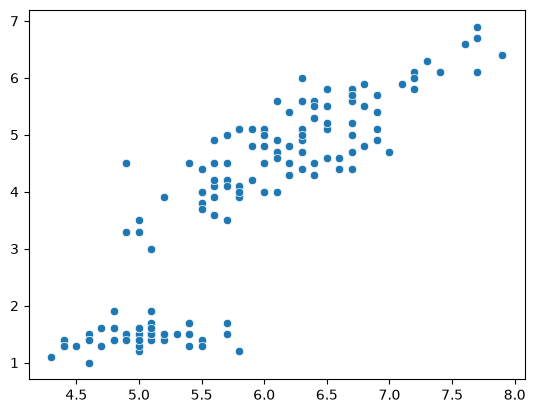

In [5]:
# Visualize
sns.scatterplot(x=X[:,0], y=X[:,2])

In [6]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [7]:
# optional - dimensionality reduciton using PCA
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

pca_data = pca.fit_transform(X_scaled)


## Elbow method
WCSS (inertia) always falls as *k* grows; the *elbow* where the drop flattens suggests a good *k*.

In [8]:
# Elbow method
wcss = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(pca_data)
    wcss.append(kmeans.inertia_)

<Axes: >

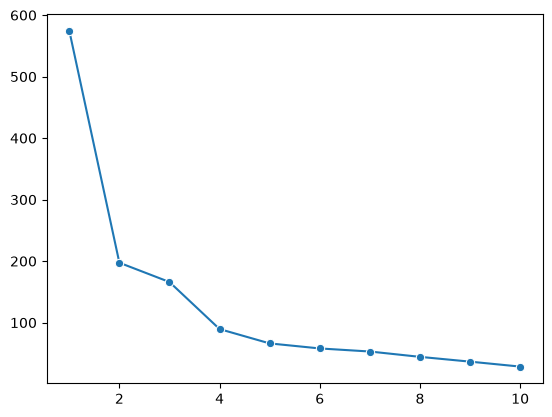

In [9]:
sns.lineplot(x=range(1, 11), y=wcss, marker='o')

<Axes: >

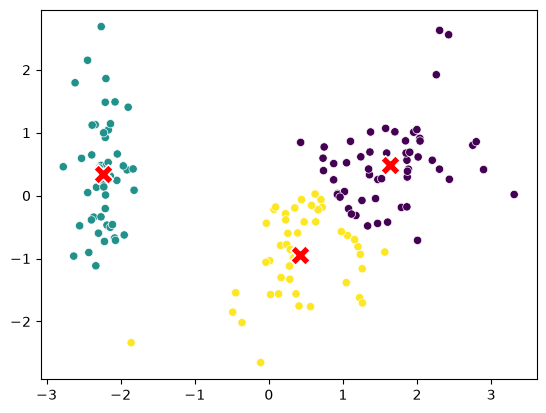

In [10]:
# KMeans

kmeans = KMeans(n_clusters=3, random_state=10)
labels = kmeans.fit_predict(pca_data)

sns.scatterplot(x=pca_data[:, 0], y=pca_data[:,1], c=labels)
sns.scatterplot(x=kmeans.cluster_centers_[:, 0], y=kmeans.cluster_centers_[:, 1], marker="X", c="red", s=200)

## How good are the clusters?

In [11]:
from sklearn.metrics import silhouette_score, adjusted_rand_score

print("silhouette score:", silhouette_score(pca_data, labels))
# The true labels are NOT used for clustering - only to check afterwards how well clusters match them
print("adjusted Rand index vs true labels:", adjusted_rand_score(y, labels))

silhouette score: 0.5049971595655939
adjusted Rand index vs true labels: 0.645147003482001
